**Aim:** To apply Principal Component Analysis (PCA) to the Iris dataset, reduce its four numerical features to 2 principal components and 3 principal components, and compare how much of the original data variance is explained by each representation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Step 1: Load the dataset
df = pd.read_csv("iris.csv")

print("Dataset:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset shape: (150, 5)

Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


**Dataset description**:
The Iris dataset typically contains 150 flower samples, three species, and four numerical features.
Features	are	Sepal length in cm,	Sepal width	in cm,	Petal length in cm,	Petal width in cm	and	Species	are	Iris-setosa, Iris-versicolor, or Iris-virginica.	The four numerical features will be reduced to two or three new features using PCA. The Species column is retained only for visualization, not for calculating PCA.

In [3]:
# Step 2: Separate features and target
# Assumes the last column contains the species label
X = df.select_dtypes(include=np.number)
y = df.loc[X.index, df.columns.difference(X.columns)[0]] \
    if len(df.columns.difference(X.columns)) > 0 else None

# Check for missing values
print("\nMissing values:")
print(X.isnull().sum())

# Handle missing numerical values if present
X = X.fillna(X.mean())


Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
dtype: int64


In [4]:
# Step 3: Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# Step 4: Apply PCA with 2 components
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

print("\n--- PCA with 2 Components ---")
print("Reduced data shape:", X_pca2.shape)
print("Explained variance ratio (%):",
      np.round(pca2.explained_variance_ratio_ * 100, 2))
print("Total explained variance (%):",
      round(sum(pca2.explained_variance_ratio_) * 100, 2))


--- PCA with 2 Components ---
Reduced data shape: (150, 2)
Explained variance ratio (%): [72.77 23.03]
Total explained variance (%): 95.8


In [6]:
# Step 5: Apply PCA with 3 components
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("\n--- PCA with 3 Components ---")
print("Reduced data shape:", X_pca3.shape)
print("Explained variance ratio (%):",
      np.round(pca3.explained_variance_ratio_ * 100, 2))
print("Total explained variance (%):",
      round(sum(pca3.explained_variance_ratio_) * 100, 2))


--- PCA with 3 Components ---
Reduced data shape: (150, 3)
Explained variance ratio (%): [72.77 23.03  3.68]
Total explained variance (%): 99.48


In [7]:
# Step 6: Create reduced datasets
result2 = pd.DataFrame(X_pca2, columns=["PC1", "PC2"])
result3 = pd.DataFrame(X_pca3, columns=["PC1", "PC2", "PC3"])

if y is not None:
    result2["Species"] = y.values
    result3["Species"] = y.values

print("\nFirst five records with 2 PCs:")
print(result2.head().round(3))

print("\nFirst five records with 3 PCs:")
print(result3.head().round(3))


First five records with 2 PCs:
     PC1    PC2 Species
0 -2.265  0.506  setosa
1 -2.086 -0.655  setosa
2 -2.368 -0.318  setosa
3 -2.304 -0.575  setosa
4 -2.389  0.675  setosa

First five records with 3 PCs:
     PC1    PC2    PC3 Species
0 -2.265  0.506  0.122  setosa
1 -2.086 -0.655  0.227  setosa
2 -2.368 -0.318 -0.051  setosa
3 -2.304 -0.575 -0.099  setosa
4 -2.389  0.675 -0.021  setosa


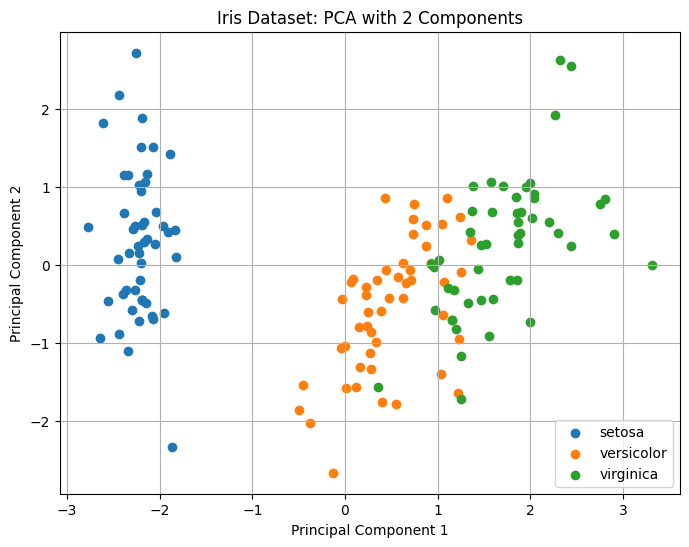

In [8]:
# Step 7: Visualize 2 principal components
plt.figure(figsize=(8, 6))

if y is not None:
    for species in y.unique():
        mask = (y == species).values
        plt.scatter(
            X_pca2[mask, 0],
            X_pca2[mask, 1],
            label=species
        )
    plt.legend()
else:
    plt.scatter(X_pca2[:, 0], X_pca2[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset: PCA with 2 Components")
plt.grid(True)
plt.show()

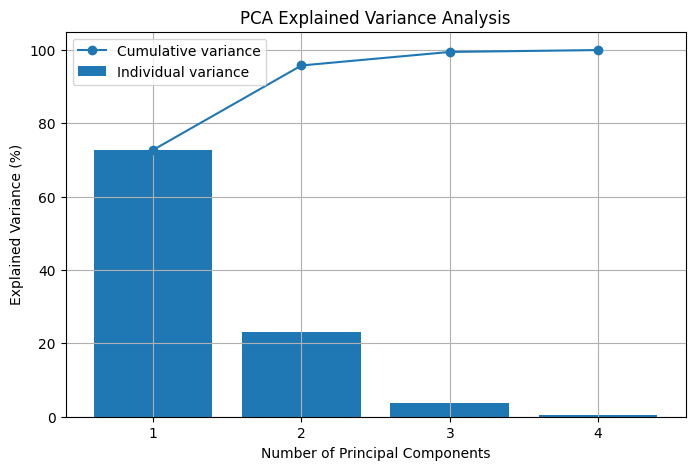

In [9]:
# Step 8: Visualize explained variance
pca_all = PCA()
pca_all.fit(X_scaled)

individual = pca_all.explained_variance_ratio_ * 100
cumulative = np.cumsum(individual)

plt.figure(figsize=(8, 5))
components = np.arange(1, len(individual) + 1)

plt.bar(components, individual, label="Individual variance")
plt.plot(
    components, cumulative,
    marker="o", label="Cumulative variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance Analysis")
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()